In [28]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\dipal\Downloads\cafe_sales_raw.csv")
df.head(10)

,order_id,date,item,category,price,quantity,payment_method,staff
0,1038,2026-09-01,Tea,Beverages,2.5,4.0,UPI,Aman
1,1137,2026-07-18,juice,Beverages,4.0,1.0,Cash,Riya
2,1009,2026-08-13,Tea,Beverages,2.5,1.0,Card,Aman
3,1121,2026-09-03,Brownie,Desserts,3.5,4.0,UPI,Riya
4,1229,2026-07-20,Juice,Beverages,4.0,1.0,Upi,Karan
5,1280,2026-07-25,Tea,Beverages,2.5,4.0,Card,Aman
6,1203,2026-08-25,Juice,Beverages,4.0,1.0,Card,Riya
7,1418,17/09/2026,Brownie,Desserts,3.5,1.0,UPI,Aman
8,1600,11/09/2026,Sandwich,Food,6.0,3.0,Cash,Riya
9,1452,"Jul 04, 2026",Tea,Beverages,2.5,1.0,UPI,Karan


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 625 entries, 0 to 624
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        625 non-null    int64  
 1   date            625 non-null    str    
 2   item            625 non-null    str    
 3   category        625 non-null    str    
 4   price           590 non-null    float64
 5   quantity        593 non-null    float64
 6   payment_method  625 non-null    str    
 7   staff           600 non-null    str    
dtypes: float64(2), int64(1), str(5)
memory usage: 58.9 KB


In [30]:
df.describe()

,order_id,price,quantity
count,625.000000,590.000000,593.000000
mean,1300.300800,4.451695,2.819562
std,173.665717,3.224054,20.483006
min,1001.000000,2.500000,-2.000000
25%,1151.000000,3.500000,1.000000
50%,1299.000000,4.000000,2.000000
75%,1450.000000,4.500000,3.000000
max,1600.000000,75.000000,500.000000


In [31]:
df.isna().sum()

order_id           0
date               0
item               0
category           0
price             35
quantity          32
payment_method     0
staff             25
dtype: int64

In [32]:
df.duplicated().sum()

np.int64(25)

In [33]:
df["item"].value_counts()

item
Juice            85
Brownie          81
Cake             69
Coffee           69
Sandwich         65
Tea              64
Cold Coffee      63
Burger           57
sandwich          9
juice             6
cake              6
 Coffee           5
BROWNIE           4
 Tea              4
coffee            4
tea               4
COFFEE            3
TEA               3
cold coffee       3
BURGER            2
 Cake             2
COLD COFFEE       2
 Burger           2
brownie           2
JUICE             2
 Cold Coffee      2
SANDWICH          2
 Sandwich         1
 Brownie          1
CAKE              1
burger            1
 Juice            1
Name: count, dtype: int64

In [34]:
df["payment_method"].value_counts()

payment_method
Card     199
Cash     195
UPI      190
Cash       9
U.P.I      9
Upi        8
cash       8
CARD       6
 card      1
Name: count, dtype: int64

In [35]:
df["category"].value_counts()

category
Beverages     294
Desserts      151
Food          128
beverages      11
Beverages       8
DESSERTS        7
BEVERAGES       7
desserts        6
food            5
FOOD            4
Desserts        2
Food            2
Name: count, dtype: int64

In [36]:
df["date"].head(15)

0       2026-09-01
1       2026-07-18
2       2026-08-13
3       2026-09-03
4       2026-07-20
5       2026-07-25
6       2026-08-25
7       17/09/2026
8       11/09/2026
9     Jul 04, 2026
10      2026-09-15
11      22/08/2026
12      2026-07-01
13      2026-09-10
14      2026-09-14
Name: date, dtype: str

In [37]:
clean = df.copy()

In [38]:
before = len(clean)
clean = clean.drop_duplicates()
print("Removed", before - len(clean), "duplicate rows")

Removed 25 duplicate rows


In [39]:
for col in ["item", "category", "payment_method"]:
    clean[col] = clean[col].str.strip().str.title()

clean["payment_method"] = clean["payment_method"].replace({"Upi": "UPI", "U.P.I": "UPI"})

In [40]:
clean["item"].value_counts()
clean["category"].value_counts()
clean["payment_method"].value_counts()

payment_method
Cash    207
UPI     199
Card    194
Name: count, dtype: int64

In [41]:
s = df["date"].astype(str).str.strip()
dates = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
dates = dates.fillna(pd.to_datetime(s, format="%d/%m/%Y", errors="coerce"))
dates = dates.fillna(pd.to_datetime(s, format="%b %d, %Y", errors="coerce"))
clean["date"] = dates
print(clean["date"].isna().sum())
print(clean["date"].min().date(), clean["date"].max().date())

0
2026-07-01 2026-09-30


In [42]:
clean.loc[clean["price"] > 20, "price"] = None
clean["price"] = clean["price"].fillna(clean.groupby("item")["price"].transform("median"))
print(clean["price"].isna().sum())

0


In [43]:
bad_qty = clean["quantity"].isna() | (clean["quantity"] <= 0) | (clean["quantity"] > 20)
print("Rows removed for bad quantity:", bad_qty.sum())
clean = clean[~bad_qty]

Rows removed for bad quantity: 37


In [44]:
clean["staff"] = clean["staff"].fillna("Unknown")

In [45]:
clean["revenue"] = clean["price"] * clean["quantity"]
clean["month"] = clean["date"].dt.to_period("M").astype(str)

In [46]:
clean.info()
clean.describe()
clean.to_csv("cafe_sales_clean.csv", index=False)
print(len(df), "rows before ->", len(clean), "rows after")

<class 'pandas.DataFrame'>
Index: 563 entries, 0 to 624
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        563 non-null    int64         
 1   date            563 non-null    datetime64[us]
 2   item            563 non-null    str           
 3   category        563 non-null    str           
 4   price           563 non-null    float64       
 5   quantity        563 non-null    float64       
 6   payment_method  563 non-null    str           
 7   staff           563 non-null    str           
 8   revenue         563 non-null    float64       
 9   month           563 non-null    str           
dtypes: datetime64[us](1), float64(3), int64(1), str(5)
memory usage: 64.5 KB
625 rows before -> 563 rows after


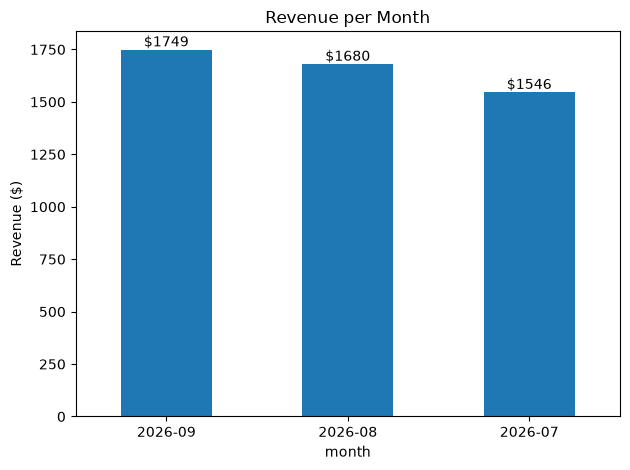

In [49]:
monthly = clean.groupby("month")["revenue"].sum().sort_values(ascending=False)
ax = monthly.plot(kind="bar", title="Revenue per Month")
ax.bar_label(ax.containers[0], fmt="$%.0f")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("revenue_per_month.png", dpi=150)
plt.show()

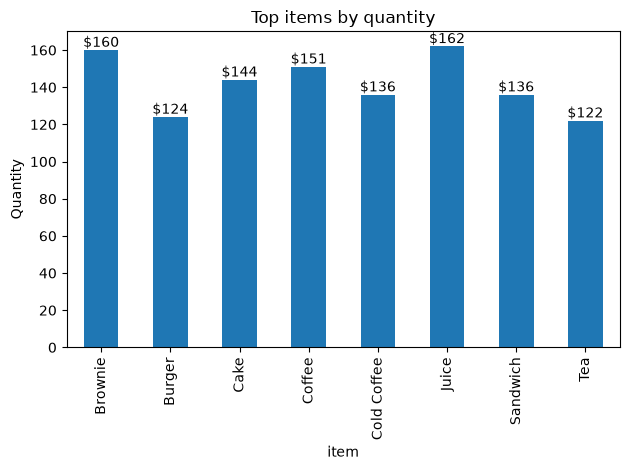

In [51]:
monthly = clean.groupby("item")["quantity"].sum()
ax = monthly.plot(kind="bar", title="Top items by quantity")
ax.bar_label(ax.containers[0], fmt="$%.0f")
plt.ylabel("Quantity")
plt.tight_layout()
plt.savefig("Top_items_by_quantity.png", dpi=150)
plt.show()

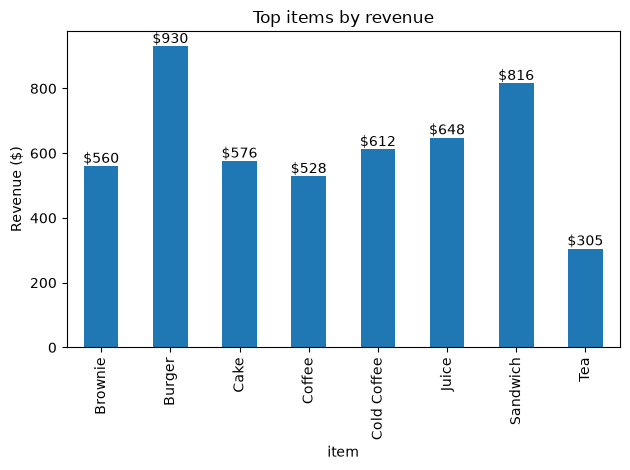

In [52]:
monthly = clean.groupby("item")["revenue"].sum()
ax = monthly.plot(kind="bar", title="Top items by revenue")
ax.bar_label(ax.containers[0], fmt="$%.0f")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.savefig("Top_items_by_revenue.png", dpi=150)
plt.show()

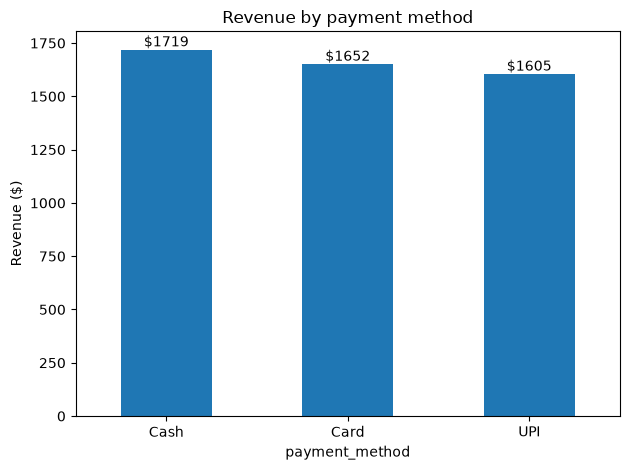

In [23]:
pay = clean.groupby("payment_method")["revenue"].sum().sort_values(ascending=False)
ax = pay.plot(kind="bar", title="Revenue by payment method")
ax.bar_label(ax.containers[0], fmt="$%.0f")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("4_payment_methods.png", dpi=150)
plt.show()

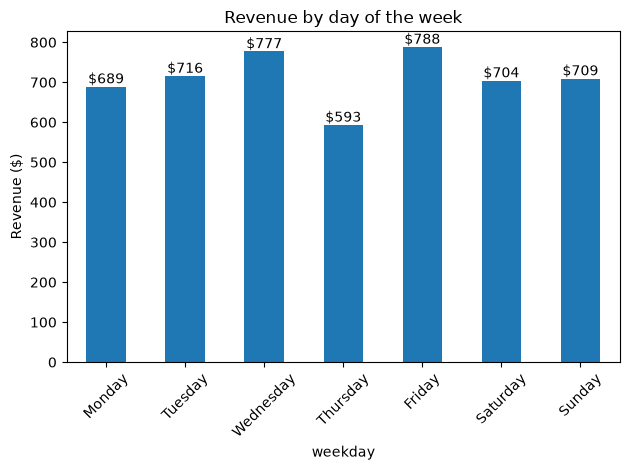

In [25]:
clean["weekday"] = clean["date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wk = clean.groupby("weekday")["revenue"].sum().reindex(order)
ax = wk.plot(kind="bar", title="Revenue by day of the week")
ax.bar_label(ax.containers[0], fmt="$%.0f")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("5_revenue_by_weekday.png", dpi=150)
plt.show()